# Bonus B9: How to compose LangChain's building blocks

## Goal

We build two support-desk pipelines from LangChain's smaller pieces, with no agent in them: one drafts the reply to a
ticket, the other turns a ticket into a typed record. The pieces are a prompt template that fills the same reply
instructions for any ticket, a chain written `prompt | model | parser` that hands each step's result to the next, a
model that returns a Pydantic object, and the same chain run over many tickets at once or streamed piece by piece. The
moment that teaches it is in Part C: the duplicate-charge ticket comes back as a valid `TicketRecord`, and a record
with an invoice number that appears nowhere in the ticket passes the same validation. Only a check in our own code can
say whether a value came from the ticket. Part E then asks what every pipeline meets sooner or later: our code fixed
these steps, so when is that better than an agent that chooses its own?

## What you will learn

- How to write a `ChatPromptTemplate` with variables, and read the messages it actually sends.
- How to compose `prompt | model | StrOutputParser()` into one chain, and what each step hands the next.
- How to turn a ticket into a typed record with `with_structured_output`: the request the API receives, the raw reply
  beside the parsed object, and what validation guarantees and what it does not.
- How to run one chain over several tickets with `batch`, stream one reply as it is written, and price both from the
  token counts.
- How to put a step of our own, a database lookup, inside a chain.
- When a fixed chain (a workflow) is the better choice, and when you need an agent such as lab 08's `create_agent`.

## Where this lab starts

Lab 08 Part A constructed `ChatOpenAI` from `models.env`, sent it a list of messages with `invoke`, and read the
`AIMessage` that came back: its words in `.text`, its token counts in `usage_metadata`, and in `response_metadata`
what the API itself returned. Lab 08 then handed that model to `create_agent`, which runs a loop. This lab stays with
one model call at a time and builds around it: what goes in (a prompt made from a template), what comes out (a
string, or a typed record), and how to run it on many inputs. It defines everything it uses, so it runs without lab 08.

The picture shows the two shapes this lab compares. On top, the chain we build: our code fixed the three steps, and
each arrow is labelled with the object one step hands the next. Below, the agent of lab 08, where the model's reply
decides whether the loop goes round again. The black boxes are the model's work; the lime boxes run our code.

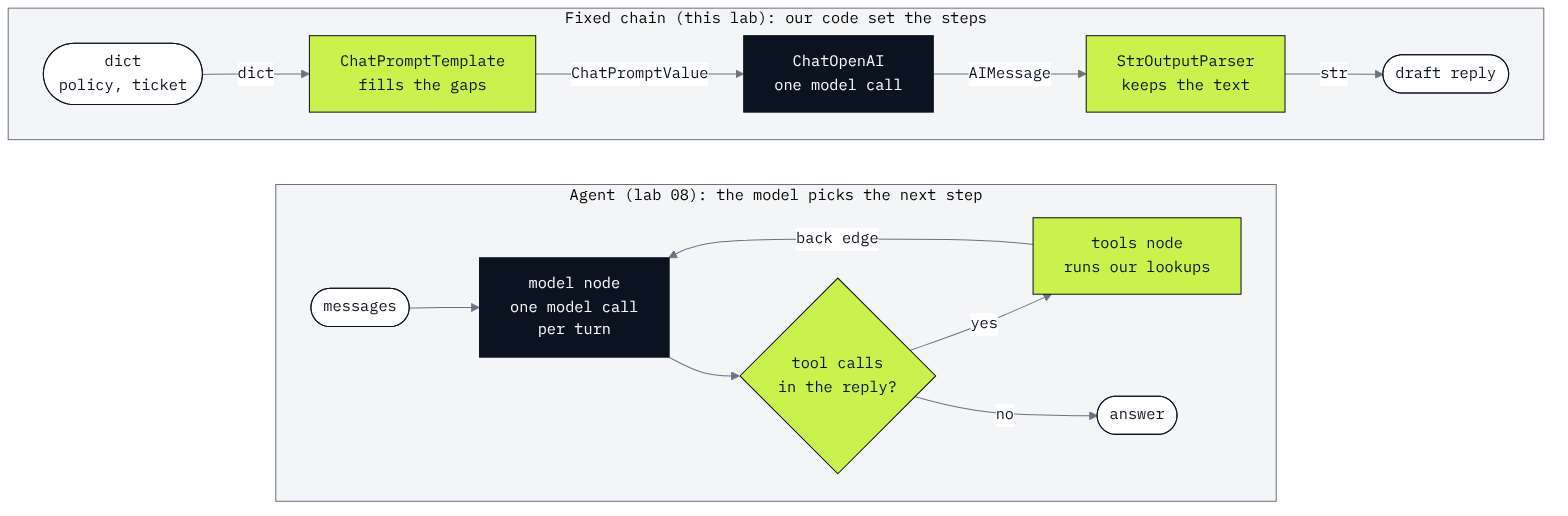

In [1]:
from IPython.display import Image

Image("../resources/labB9_chain_and_agent.png", width=760)

Notice where the decision sits. In the chain there is no box that chooses: every input goes through the same three
steps. In the agent, the route after the model depends on what the model wrote. Part E comes back to this.

---

## Setup

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the model and the
prices from there, and finds your key without printing it ([Lab 00](../../../00_Environment_Check/README.md) reads it
line by line).

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The model object is built exactly as in lab 08, with two settings from `models.env`:

- `model=MODEL`: the model name.
- `reasoning_effort=EFFORT`: the reasoning effort, `none` here. When `models.env` sets no effort, `EFFORT` is `None`
  and `ChatOpenAI` leaves the setting out of the request.

With this setting and no tools, `ChatOpenAI` sends each call to OpenAI's Chat Completions API, and the reply's
`content` is a plain string (lab 08 Part A checked this by the response id, which starts with `chatcmpl-`). Constructing
the object makes no call.

In [3]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT)
print(type(llm).__name__, "| model:", llm.model_name, "| reasoning effort:", llm.reasoning_effort)

ChatOpenAI | model: gpt-6-luna | reasoning effort: none


The shop's support files are in `data/corpus/`: 20 short policies and 16 tickets, Markdown files read in place.
`CORPUS.glob("ticket_*.md")` finds the files whose names match the pattern, and `sorted` puts them in name order.

In [4]:
CORPUS = ROOT / "data" / "corpus"
tickets = sorted(path.name for path in CORPUS.glob("ticket_*.md"))
print(len(tickets), "tickets")
for name in tickets:
    print(" ", name)

16 tickets
  ticket_01_helena_wrong_album.md
  ticket_02_puja_download_expired.md
  ticket_03_usa_tax_question.md
  ticket_04_canada_free_shipping.md
  ticket_05_brazil_customs.md
  ticket_06_germany_warped_vinyl.md
  ticket_07_uk_preorder_delay.md
  ticket_08_france_gift_card.md
  ticket_09_india_region_lock.md
  ticket_10_chile_student_discount.md
  ticket_11_ireland_exchange.md
  ticket_12_portugal_split_parcel.md
  ticket_13_hungary_account_email.md
  ticket_14_duplicate_invoice.md
  ticket_15_library_transfer.md
  ticket_16_overpayment_note.md


Sixteen tickets. Each is a short note a rep wrote: the customer or their country, what happened, and the decision,
under a `Status:` line. We use a handful of them. Ticket 16 stays out of this lab on purpose: it carries a planted
instruction, which lab 17 studies.

---

## Part A: Fill the same reply instructions for any ticket with a prompt template

A rep sends the same kind of reply many times a day: a few sentences that explain the decision, quote the rule
behind it and promise nothing the policy does not allow. Those instructions stay the same; the ticket and the policy
change. This part writes the instructions once, with named gaps for what changes, and checks what is actually sent.

Here is one ticket and the policy that decides it.

In [5]:
ticket = (CORPUS / "ticket_10_chile_student_discount.md").read_text()
policy = (CORPUS / "policy_student_discount.md").read_text()
print(ticket)
print(policy)

# Ticket 10 — Chile, student discount after invoice

Date: 2011-04-03
Customer: billing country Chile

Customer sent a student email after checkout and asked for 10 percent back. Policy: student discount is applied at checkout only.

Status: closed. No credit.

# Student discount

A verified student email (ending in .edu or the local equivalent) gets 10 percent off physical items. Digital albums are not discounted.

The discount is applied at checkout. We do not add it after the invoice exists.

The discount cannot be stacked with gift-card promotions.



The customer in Chile asked for the 10 percent student discount after checkout, and the ticket records the decision:
`No credit.` The policy holds the rule behind it: *The discount is applied at checkout. We do not add it after the
invoice exists.* A good reply explains exactly that.

First the plain version, the way lab 08 wrote messages: a `SystemMessage` with the instructions and the policy, a
`HumanMessage` with the ticket, put together with `+`.

In [6]:
from langchain_core.messages import HumanMessage, SystemMessage

REPLY_RULES = ("You draft replies for the support reps of a music shop. Write to the customer in at most four "
               "sentences. Explain the decision recorded in the ticket, using only the policy below, and quote the "
               "rule you rely on. Promise nothing the policy does not allow. Sign off as 'The Chinook support team'.")

messages = [
    SystemMessage(REPLY_RULES + "\n\nPolicy:\n" + policy),
    HumanMessage("Ticket:\n" + ticket + "\n\nDraft the reply."),
]
print([type(message).__name__ for message in messages])

['SystemMessage', 'HumanMessage']


Two messages, ready to send. For the next ticket we would build both strings again, and anyone who changes the rules
has to find every place they were pasted. A **prompt template** holds the fixed text once, with named gaps written in
curly braces: `{policy}` and `{ticket}`.

`ChatPromptTemplate.from_messages` takes a list of `(role, text)` pairs: `"system"` and `"human"` become a
`SystemMessage` and a `HumanMessage` when the template is filled. Like the model, the template makes no call when it
is constructed.

In [7]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", REPLY_RULES + "\n\nPolicy:\n{policy}"),
    ("human", "Ticket:\n{ticket}\n\nDraft the reply."),
])
print(type(prompt).__name__)
print("variables:", prompt.input_variables)

ChatPromptTemplate
variables: ['policy', 'ticket']


`input_variables` is `['policy', 'ticket']`: the template found the two names inside the braces and expects a value
for each. Filling it is `invoke` with a dictionary from variable name to text, the same `invoke` the model has.

In [8]:
prompt_value = prompt.invoke({"policy": policy, "ticket": ticket})
print(type(prompt_value).__name__)
for message in prompt_value.to_messages():
    print(f"--- {type(message).__name__}")
    print(message.content)

ChatPromptValue
--- SystemMessage
You draft replies for the support reps of a music shop. Write to the customer in at most four sentences. Explain the decision recorded in the ticket, using only the policy below, and quote the rule you rely on. Promise nothing the policy does not allow. Sign off as 'The Chinook support team'.

Policy:
# Student discount

A verified student email (ending in .edu or the local equivalent) gets 10 percent off physical items. Digital albums are not discounted.

The discount is applied at checkout. We do not add it after the invoice exists.

The discount cannot be stacked with gift-card promotions.

--- HumanMessage
Ticket:
# Ticket 10 — Chile, student discount after invoice

Date: 2011-04-03
Customer: billing country Chile

Customer sent a student email after checkout and asked for 10 percent back. Policy: student discount is applied at checkout only.

Status: closed. No credit.


Draft the reply.


`invoke` returned a `ChatPromptValue`, the filled prompt. `to_messages()` gives the list a model receives: a
`SystemMessage` holding the rules with the student-discount policy in the gap, and a `HumanMessage` holding the
ticket. This is what will be sent; nothing is added later. Is it the same as the list we wrote by hand?

In [9]:
print("same as by hand:", prompt_value.to_messages() == messages)

same as by hand: True


`True`: the template builds the same messages, so from here on the rules live in one place. Message objects compare
by their type and fields, so `==` checks every word.

**What does a template check?** Only that every variable has a value. Forget one and see.

In [10]:
try:
    prompt.invoke({"ticket": ticket})
except KeyError as error:
    print("KeyError:", error.args[0].splitlines()[0])

KeyError: Input to ChatPromptTemplate is missing variables {'policy'}.  Expected: ['policy', 'ticket'] Received: ['ticket']


The template refuses before any model call: `Input to ChatPromptTemplate is missing variables {'policy'}. Expected:
['policy', 'ticket'] Received: ['ticket']`. (`try` and `except KeyError` catch the error so that we can print its
first line and carry on.)

What it does not check is the value: an empty string, or the wrong policy, fills the gap just as happily. Choosing the
right policy for a ticket is still our job; Part D does it with a small dictionary.

**Important:** every `{` in a template starts a variable. If the rules ever contain a literal brace, such as a JSON
example, write it twice (`{{` and `}}`), or the template will expect a variable with that name.

**Checkpoint A.** `variables: ['policy', 'ticket']`; a `ChatPromptValue` whose two messages hold the rules with the
policy, and the ticket; `same as by hand: True`; the `KeyError` naming `{'policy'}`. A pass shows the template builds
exactly the messages we meant to send; it says nothing yet about the reply.

---

## Part B: Compose prompt, model and parser into one chain

A draft needs three steps: fill the prompt, call the model, take the words out of its reply. Each step hands an object
to the next. We run them one at a time first, so each object has been seen before a chain hides it.

Step 1, filling the prompt, is Part A's `prompt.invoke`, so `prompt_value` is ready. Step 2, the model, takes it
directly: `llm.invoke` accepts a `ChatPromptValue` as well as a list of messages.

In [11]:
reply = llm.invoke(prompt_value)
print(type(reply).__name__, "| content:", type(reply.content).__name__, "| id starts:", reply.response_metadata["id"][:9])
print(reply.text)

AIMessage | content: str | id starts: chatcmpl-
The student discount can’t be added after an invoice has been issued, so no credit was applied. The policy states, “We do not add it after the invoice exists.”  
The Chinook support team


An `AIMessage` whose `content` is a `str`, and an id that starts with `chatcmpl-`: the call went to Chat Completions,
as the Setup said. The draft explains the decision (the discount cannot be added once an invoice has been issued, so
no credit) and signs off as asked, on a line of its own. It quotes only the second sentence of the rule, *We do not
add it after the invoice exists.*, and never says in words that the discount is applied at checkout.

Step 3 takes the words out of the message. We would write `reply.text`; LangChain has an object for this step,
`StrOutputParser`. We try it first on two messages we make ourselves: one whose `content` is a string, and one whose
`content` is a list of blocks, the shape lab 08's agent answer had when the Responses API answered.

In [12]:
from langchain_core.messages import AIMessage
from langchain_core.output_parsers import StrOutputParser

parser = StrOutputParser()
as_string = AIMessage(content="Hello")
as_blocks = AIMessage(content=[{"type": "text", "text": "Hello"}])
print(repr(parser.invoke(as_string)))
print(repr(parser.invoke(as_blocks)))

'Hello'
'Hello'


`'Hello'` both times. The parser reads a message's text the way `.text` does, so the step works whichever API
answered, and the string-or-list surprise of lab 08 Part C cannot reach the code after it.

Notice that the template, the model and the parser all have the same method, `invoke`: one input in, one output out.
In LangChain anything with `invoke` (and with `batch` and `stream`, which Part D uses) is a **Runnable**, and Runnables
can be joined with `|`. In plain Python `|` means "or"; LangChain's objects redefine it to mean "send my output to the
next step". This way of writing a pipeline is called the **LangChain Expression Language** (LCEL).

In [13]:
chain = prompt | llm | parser
print(type(chain).__name__)
print([type(step).__name__ for step in chain.steps])

RunnableSequence
['ChatPromptTemplate', 'ChatOpenAI', 'StrOutputParser']


`prompt | llm | parser` built a `RunnableSequence`, a Runnable that holds the three steps, in order, in its `steps`
list. Nothing ran: `|` only joins. A sequence can describe itself as a graph, as lab 08's agent did; we print the
names of its nodes.

In [14]:
print([node.name for node in chain.get_graph().nodes.values()])

['PromptInput', 'ChatPromptTemplate', 'ChatOpenAI', 'StrOutputParser', 'StrOutputParserOutput']


Five nodes: `PromptInput` (the dictionary we pass in), the three steps, and `StrOutputParserOutput` (what comes out).
They form a straight line. Lab 08's agent graph had an edge from its tools node back to the model; this one has no edge
back and no branch, so every input takes the same path. Now run it, with the same dictionary as before.

In [15]:
draft = chain.invoke({"policy": policy, "ticket": ticket})
print(type(draft).__name__, "| is a str:", isinstance(draft, str))
print(draft)

TextAccessor | is a str: True
Because your order had already been invoiced, we can’t apply the student discount or issue a credit afterward. The rule is: “The discount is applied at checkout. We do not add it after the invoice exists.”  
The Chinook support team


The type is `TextAccessor`, and `isinstance` says it is a `str`: `TextAccessor` is LangChain's subclass of `str`,
the same type `.text` returns, kept so that older code calling `.text()` as a method still works. Everything we do
with a string works on it, so from here on we call it a string.

It is a second model call, so the wording differs from Step 2's draft: the same decision (no discount and no credit
once the order was invoiced), and this time the rule quoted in full, both sentences, where Step 2's draft quoted only
the second.

What `chain.invoke` did, step by step:

1. `prompt.invoke(dictionary)` filled the template and returned a `ChatPromptValue`.
2. `llm.invoke(prompt_value)` sent the two messages and returned an `AIMessage`.
3. `parser.invoke(ai_message)` returned the message's text as a string.

**What did the string leave behind?** The `AIMessage` carried `usage_metadata` (the tokens) and the response id; the
parser kept only the words. The draft is easy to use, but it no longer says what it cost. Part D counts the tokens of a whole
chain anyway, with a callback.

**Checkpoint B.** `AIMessage`, `content` a `str`, an id starting `chatcmpl-`; `'Hello'` twice from the parser; a
`RunnableSequence` with steps `['ChatPromptTemplate', 'ChatOpenAI', 'StrOutputParser']` and five graph nodes in a line;
`draft` a `TextAccessor` with `is a str: True`. A pass shows the chain runs our three steps in our order; whether a draft is good is for a person,
or a check, to read.

---

## Part C: Turn a ticket into a typed record with `with_structured_output`

Some tickets need a record, not a reply: the duplicate-charge ticket should become fields that our code can check and
put in a refund queue. A sentence would make our code pick numbers out of words. This part asks the model for an
object instead, reads exactly what the API was asked, and finds what validation can and cannot promise.

The ticket first.

In [16]:
dup_ticket = (CORPUS / "ticket_14_duplicate_invoice.md").read_text()
print(dup_ticket)

# Ticket 14 — Duplicate digital charge

Date: 2013-11-02
Customer: email on file, digital album The Essential Miles Davis

Two invoices, same album, same day, 9.99 each. Refunds policy: refund the later invoice in full.

Status: open. Assigned representative still reviewing both invoice numbers.



Read what it says and what it leaves out. It says: two invoices for the same digital album on the same day, 9.99 US
dollars each, and the refunds policy's rule (refund the later invoice). It does not give a customer name (only
*email on file*) or the invoice numbers (the rep is *still reviewing both invoice numbers*).

Here is the record we want, written by hand from the ticket:

In [17]:
wanted = {"issue_type": "duplicate_charge", "amount_usd": 9.99, "invoice_numbers": [],
          "customer_name": None, "needs_refund": True}
print(wanted)

{'issue_type': 'duplicate_charge', 'amount_usd': 9.99, 'invoice_numbers': [], 'customer_name': None, 'needs_refund': True}


Five fields:

- `issue_type`: one of a few fixed labels our code can route on.
- `amount_usd`: the amount the ticket names, 9.99.
- `invoice_numbers`: an empty list, because the ticket gives none.
- `customer_name`: `None`, Python's "no value", because the ticket names nobody.
- `needs_refund`: `True`, since the customer was charged twice.

The empty list and the `None` matter: an honest record says what the ticket does not say.

Now the same shape as a **Pydantic model**, a class that lists each field with its type and checks values against
it. Three types are new here:

- `Literal["duplicate_charge", ...]` allows only the listed strings.
- `float | None` allows a number or `None`.
- `list[int]` is a list of whole numbers.

`Field(description=...)` adds a sentence that is sent to the model with the schema, so we write each one as an
instruction.
`model_validate` checks a dictionary against the class and returns an object.

In [18]:
from typing import Literal

from pydantic import BaseModel, Field, ValidationError


class TicketRecord(BaseModel):
    """One support ticket as fields a refund queue can check."""
    issue_type: Literal["duplicate_charge", "refund_request", "shipping", "damaged_item", "download", "other"]
    amount_usd: float | None = Field(description="The amount the ticket names, in US dollars; null if it names none")
    invoice_numbers: list[int] = Field(description="Invoice numbers written in the ticket; empty if it gives none")
    customer_name: str | None = Field(description="The customer's name as the ticket writes it; null if it has none")
    needs_refund: bool


print(repr(TicketRecord.model_validate(wanted)))

TicketRecord(issue_type='duplicate_charge', amount_usd=9.99, invoice_numbers=[], customer_name=None, needs_refund=True)


Our hand-written dictionary passes: `model_validate` returned a `TicketRecord` whose fields we can read with dots
(`record.amount_usd`). Next, the model fills the same class.

`llm.with_structured_output(TicketRecord)` returns a new Runnable: the same model, told to answer in the shape of
`TicketRecord`, followed by a step that turns the reply into a `TicketRecord`. Before calling it, we look inside.

In [19]:
extract = llm.with_structured_output(TicketRecord)
print(type(extract).__name__, "with", len(extract.steps), "steps")
print("bound to the model:", list(extract.first.kwargs))
print("response_format:", extract.first.kwargs["response_format"])
print("method:", extract.first.kwargs["ls_structured_output_format"]["kwargs"]["method"])

RunnableSequence with 2 steps
bound to the model: ['response_format', 'ls_structured_output_format']
response_format: <class '__main__.TicketRecord'>
method: json_schema


It is a chain too, a `RunnableSequence` of two steps:

1. `extract.first`: our model with extra arguments bound to every call. `response_format` is the `TicketRecord`
   class itself; `ls_structured_output_format` is a label LangChain keeps for tracing.
2. `extract.last`: the parser that reads the reply into a `TicketRecord`.

The method is `json_schema`, `ChatOpenAI`'s default: the schema is sent as the format the reply's text must take.
(The other method, `function_calling`, sends the schema as a tool; with this model, a request that carries a tool
goes to the Responses API, as lab 08 Part C found.)

Since `extract` is a Runnable, it can follow a prompt with `|`, exactly like the model in Part B. The prompt gives the
extraction its instruction:

In [20]:
extract_prompt = ChatPromptTemplate.from_messages([
    ("system", "Turn the support ticket into a record. Use only what the ticket says."),
    ("human", "{ticket}"),
])
print(extract_prompt.input_variables)

['ticket']


One variable, `ticket`.

**What exactly does the API receive?** To read the request itself, we make a second model object with the same two
settings and one addition: its own HTTP client, `DefaultHttpxClient` from the `openai` package, with an **event
hook**, a function the client calls with every request just before sending it. Our hook is `requests_sent.append`, so
each request lands in a list we can read. Normal code does not need this; it is here only so we can look.

`include_raw=True` asks `with_structured_output` to return the raw reply beside the parsed object.

In [21]:
import json

from openai import DefaultHttpxClient

requests_sent = []
seen_llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT,
                      http_client=DefaultHttpxClient(event_hooks={"request": [requests_sent.append]}))

seen_chain = extract_prompt | seen_llm.with_structured_output(TicketRecord, include_raw=True)
result = seen_chain.invoke({"ticket": dup_ticket})
print(list(result), "|", len(requests_sent), "request sent")

['raw', 'parsed', 'parsing_error'] | 1 request sent


The result is a dictionary with three keys, `raw`, `parsed` and `parsing_error`, and the hook caught one request. The
request first: its method and address, the top-level keys of its JSON body, and the `response_format` it carried.

In [22]:
request = requests_sent[-1]
body = json.loads(request.content)
print(request.method, request.url.path)
print("keys sent:", list(body))
print(json.dumps(body["response_format"], indent=1))

POST /v1/chat/completions
keys sent: ['model', 'stream', 'messages', 'reasoning_effort', 'response_format']
{
 "type": "json_schema",
 "json_schema": {
  "schema": {
   "description": "One support ticket as fields a refund queue can check.",
   "properties": {
    "issue_type": {
     "enum": [
      "duplicate_charge",
      "refund_request",
      "shipping",
      "damaged_item",
      "download",
      "other"
     ],
     "title": "Issue Type",
     "type": "string"
    },
    "amount_usd": {
     "anyOf": [
      {
       "type": "number"
      },
      {
       "type": "null"
      }
     ],
     "description": "The amount the ticket names, in US dollars; null if it names none",
     "title": "Amount Usd"
    },
    "invoice_numbers": {
     "description": "Invoice numbers written in the ticket; empty if it gives none",
     "items": {
      "type": "integer"
     },
     "title": "Invoice Numbers",
     "type": "array"
    },
    "customer_name": {
     "anyOf": [
      {
     

Reading the request:

1. `POST /v1/chat/completions`: the Chat Completions API, because the request carries no tools.
2. The body holds `model`, `stream` (false), `messages` (our two messages), `reasoning_effort` and
   `response_format`. Nothing else steers the reply.
3. `response_format` has `"type": "json_schema"` and `"strict": true`. In **strict mode** the API constrains what
   the model can write to text that fits the schema, so the shape is enforced at the source.
4. Inside `schema`: our five properties, with the descriptions we wrote, and the `Literal` labels as an `enum`.
   The `openai` package, which turns our class into this format, adds two things for strict mode:
   `"additionalProperties": false`, which forbids extra keys, and a `required` list that names every field. So the
   model cannot leave `customer_name` out; it has to write `null` on purpose.

Now the reply: the raw message beside the parsed object.

In [23]:
raw = result["raw"]
print("raw type:", type(raw).__name__, "| id starts:", raw.response_metadata["id"][:9])
print("raw text:", raw.text)
print("parsed:  ", repr(result["parsed"]))
print("parsing_error:", result["parsing_error"])

raw type: AIMessage | id starts: chatcmpl-
raw text: {"issue_type":"duplicate_charge","amount_usd":9.99,"invoice_numbers":[],"customer_name":null,"needs_refund":true}
parsed:   TicketRecord(issue_type='duplicate_charge', amount_usd=9.99, invoice_numbers=[], customer_name=None, needs_refund=True)
parsing_error: None


- `raw` is the `AIMessage` from the API (Chat Completions again, by its id) and its text is a JSON string.
- `parsed` is a `TicketRecord` built from that string.
- `parsing_error` is `None`. With `include_raw=True`, a reply that cannot be read into the class (a refusal, for
  example) lands here as the exception instead of stopping the chain.

Compared with `wanted`, all five fields match: `invoice_numbers` came back as an empty list and `customer_name` as
`None`, so the model left out what the ticket does not say, and the record prints exactly like the one we wrote by
hand.

### What validation guarantees, and what it does not

Two records we make ourselves show the boundary. The first has an amount written in words; the second invents an
invoice number. `{**wanted, "amount_usd": ...}` copies `wanted` into a new dictionary and replaces that one field;
`wanted` itself is unchanged.

In [24]:
try:
    TicketRecord.model_validate({**wanted, "amount_usd": "nine ninety-nine"})
except ValidationError as error:
    print("rejected:", error.errors()[0]["loc"], error.errors()[0]["type"])

invented = TicketRecord.model_validate({**wanted, "invoice_numbers": [404]})
print("accepted:", repr(invented))

rejected: ('amount_usd',) float_parsing
accepted: TicketRecord(issue_type='duplicate_charge', amount_usd=9.99, invoice_numbers=[404], customer_name=None, needs_refund=True)


The words are rejected: `float_parsing` on `amount_usd`. The invented invoice 404 is accepted: it is a list of whole
numbers, which is all the schema asks. **Validation checks the shape, not the truth.** Strict mode and Pydantic
together guarantee five fields of the right types; neither knows what the ticket said.

So the check that matters is ours: every number in the record must appear in the ticket. `re.findall` with the
pattern `\d+(?:\.\d+)?` finds the numbers in a text (digits, then an optional decimal part); we print them first.

In [25]:
import re

numbers_in_ticket = [float(found) for found in re.findall(r"\d+(?:\.\d+)?", dup_ticket)]
print(numbers_in_ticket)

[14.0, 2013.0, 11.0, 2.0, 9.99]


`[14.0, 2013.0, 11.0, 2.0, 9.99]`: the ticket number, the three parts of the date, and the amount. Now the check, on
the model's record and on the invented one. Each line answers one question about one record.

In [26]:
for name, record in [("model's record", result["parsed"]), ("invented record", invented)]:
    amount_ok = record.amount_usd is None or record.amount_usd in numbers_in_ticket
    invoices_ok = all(number in numbers_in_ticket for number in record.invoice_numbers)
    print(f"{name}: amount in the ticket {'✅' if amount_ok else '❌'} | "
          f"invoice numbers in the ticket {'✅' if invoices_ok else '❌'} | issue {record.issue_type}")

model's record: amount in the ticket ✅ | invoice numbers in the ticket ✅ | issue duplicate_charge
invented record: amount in the ticket ✅ | invoice numbers in the ticket ❌ | issue duplicate_charge


The invented record fails on its invoice numbers: 404 is nowhere in the ticket, though the record was valid. The
model's record passes both checks, with the issue label `duplicate_charge`: its amount, 9.99, is in the ticket, and
its invoice list is empty, so it has no number that could fail.

What a pass establishes, and what it leaves open: the numbers in the record are in the ticket. It is a coarse check
(an invoice number 2 would match the date's `02`), and it does not show that the customer really was charged twice;
that is a question for the shop's database, before anyone files a refund.

**Checkpoint C.** `TicketRecord` from `model_validate`; `extract` a `RunnableSequence` with 2 steps and method
`json_schema`; one request to `/v1/chat/completions` whose `response_format` is a strict `json_schema` with all five
fields required; `raw`, `parsed` and `parsing_error` (`None`); `float_parsing` for the amount in words; the invented
record accepted by validation and failing the invoice-number check. Then explain: why did the invented record pass
validation, and which line of code caught it?

---

## Part D: Run many tickets with `batch`, and stream one reply

A morning's queue has many tickets, and a rep watching the screen would like to see a draft appear, not wait for it.
Both are methods every Runnable has, so the chain from Part B does them unchanged: `batch` for many inputs, `stream`
for pieces of one output. This part also prices the calls, since the parser threw the token counts away.

Four closed tickets, each paired with the policy that decides it. The pairing is ours, written in a dictionary from
ticket file to policy file. (The customs rule of ticket 05 is in the shipping policy, not the international one.)

In [27]:
PAIRS = {
    "ticket_04_canada_free_shipping.md": "policy_shipping.md",
    "ticket_05_brazil_customs.md": "policy_shipping.md",
    "ticket_08_france_gift_card.md": "policy_gift_cards.md",
    "ticket_10_chile_student_discount.md": "policy_student_discount.md",
}
inputs = [{"policy": (CORPUS / policy_file).read_text(), "ticket": (CORPUS / ticket_file).read_text()}
          for ticket_file, policy_file in PAIRS.items()]
print(len(inputs), "inputs, each with keys", list(inputs[0]))

4 inputs, each with keys ['policy', 'ticket']


Four dictionaries with the template's two variables, in the order of `PAIRS`.

`chain.batch(inputs)` runs the chain on every input and returns the outputs **in the order of the inputs**. It sends
them at the same time, on threads; `config={"max_concurrency": 4}` caps how many run at once. Each one is an ordinary
call, billed as usual: `batch` is not OpenAI's Batch API, the separate service that runs requests within 24 hours at
a lower price.

To count tokens through the parser we use `get_usage_metadata_callback()`. It is a **context manager**, used with
`with`: every model call made inside the `with` block reports its `usage_metadata` to it, whichever chain made the
call. We also time the batch with `time.perf_counter()`, a clock for measuring durations.

In [28]:
import time

from langchain_core.callbacks import get_usage_metadata_callback

started = time.perf_counter()
with get_usage_metadata_callback() as batch_usage:
    drafts = chain.batch(inputs, config={"max_concurrency": 4})
batch_seconds = time.perf_counter() - started

for ticket_file, one_draft in zip(PAIRS, drafts):
    print(f"--- {ticket_file}")
    print(one_draft)
print(f"\nbatch: {len(drafts)} drafts in {batch_seconds:.1f} s")

--- ticket_04_canada_free_shipping.md
Free shipping applies to physical orders over $50 before tax, and your original $48 order did not meet that threshold. The ticket records that you added a $5 single and we reshipped the order as one parcel. The rule is: “Free shipping on physical orders over 50 dollars before tax.”  
The Chinook support team
--- ticket_05_brazil_customs.md
We’re sorry you were charged a customs fee on arrival. The ticket is closed, and no refund was issued because the policy states, “Customs fees are the customer's.” The parcel was delivered.  

The Chinook support team
--- ticket_08_france_gift_card.md
We’re unable to replace the lost gift-card code. The rule is: “Lost gift-card codes are not replaced.” The purchaser should treat the code like cash.  
The Chinook support team
--- ticket_10_chile_student_discount.md
The student discount can’t be added because your invoice already exists. The policy states, “The discount is applied at checkout. We do not add it afte

Four drafts, printed beside the ticket each answers. `zip(PAIRS, drafts)` pairs the first ticket name with the first
draft, and so on; it is right only because `batch` keeps the input order. Each draft explains its ticket's decision
with its own policy's rule, quoted word for word, and signs off as asked:

- Ticket 04: the 48-dollar order was under the threshold, the ticket's fix (a 5-dollar single added, the order
  reshipped as one parcel), and the rule *Free shipping on physical orders over 50 dollars before tax.*
- Ticket 05: an apology for the fee, then no refund, because *Customs fees are the customer's.*
- Ticket 08: the lost code is not replaced, with the rule *Lost gift-card codes are not replaced.* quoted and the
  policy's next sentence (*The purchaser should treat the code like cash.*) added without quotation marks.
- Ticket 10: no credit, with the checkout rule quoted in full.

The batch took 2.3 seconds for all four.

The tokens the callback collected:

In [29]:
print(batch_usage.usage_metadata)

{'gpt-6-luna': {'input_token_details': {'cache_read': 0, 'cache_creation': 0, 'audio': 0}, 'output_tokens': 214, 'output_token_details': {'reasoning': 0, 'audio': 0}, 'input_tokens': 806, 'total_tokens': 1020}}


A dictionary keyed by the model name the API reported, with one entry that adds up all four calls: `input_tokens`,
`output_tokens`, and in `input_token_details` the cached reads (`cache_read`) and cache writes (`cache_creation`). In
our run: 806 input tokens and 214 output tokens, with both cache counts at 0.

The price, with the per-million prices from `models.env`. Input tokens include the cached ones, so ordinary input is
the input minus the cached reads and writes; each part has its own price. (Prompt caching starts at 1,024 prompt
tokens, and these prompts are shorter, so expect zeros there.) One model ran, so the dictionary has one entry, and
`list(...)[0]` takes it.

In [30]:
usage = list(batch_usage.usage_metadata.values())[0]
cached = usage["input_token_details"].get("cache_read") or 0
written = usage["input_token_details"].get("cache_creation") or 0
ordinary = usage["input_tokens"] - cached - written

batch_dollars = (ordinary * float(settings["PRICE_INPUT_PER_MILLION"])
                 + cached * float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
                 + written * float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
                 + usage["output_tokens"] * float(settings["PRICE_OUTPUT_PER_MILLION"])) / 1_000_000
print(f"ordinary input {ordinary}, cached {cached}, written {written}, output {usage['output_tokens']}")
print(f"four drafts: ${batch_dollars:.7f}")

ordinary input 806, cached 0, written 0, output 214
four drafts: $0.0001876


Four drafts cost 0.0001876 US dollars, about two hundredths of a cent. `or 0` turns a missing count (`None`, as some
models report) into zero, so the arithmetic never fails on it.

We are about to price two more runs, so the same lines become a function, `price(usage)`. It returns the same number,
which the last line checks.

In [31]:
def price(usage):
    """US dollars for one usage dictionary, at the prices in models.env."""
    cached = usage["input_token_details"].get("cache_read") or 0
    written = usage["input_token_details"].get("cache_creation") or 0
    ordinary = usage["input_tokens"] - cached - written
    return (ordinary * float(settings["PRICE_INPUT_PER_MILLION"])
            + cached * float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
            + written * float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
            + usage["output_tokens"] * float(settings["PRICE_OUTPUT_PER_MILLION"])) / 1_000_000


print("same as above:", price(usage) == batch_dollars)

same as above: True


What did `batch` buy? The same four drafts, one after another with `invoke`, timed and priced the same way.

In [32]:
started = time.perf_counter()
with get_usage_metadata_callback() as loop_usage:
    one_by_one = [chain.invoke(one_input) for one_input in inputs]
loop_seconds = time.perf_counter() - started

loop_dollars = price(list(loop_usage.usage_metadata.values())[0])
print(f"batch:      {len(drafts)} drafts in {batch_seconds:.1f} s, ${batch_dollars:.7f}")
print(f"one by one: {len(one_by_one)} drafts in {loop_seconds:.1f} s, ${loop_dollars:.7f}")

batch:      4 drafts in 2.3 s, $0.0001876
one by one: 4 drafts in 7.2 s, $0.0001856


In our run the batch took 2.3 s and 0.0001876 US dollars, one by one took 7.2 s and 0.0001856 US dollars: about a
third of the time, for almost the same price. The batch takes about as long as its slowest call, because the four
calls overlap; one by one, the times add up. The price is about the same, since it is the same four calls, and the
small difference is the wording, which changes the output tokens (the input tokens are the same four prompts, so here
the batch's drafts were simply a little longer).

**Key lesson:** `batch` saves waiting, not money.

### Stream one reply as it is written

`chain.stream(one_input)` returns the output in pieces as the API sends them. With the parser at the end each piece is
a `str`. The loop below keeps every piece with the time it arrived and prints it with a `|` after it, so we can see
where one piece ends and the next begins. `print(..., end="|")` prints the bar instead of a new line.

In [33]:
pieces = []
started = time.perf_counter()
with get_usage_metadata_callback() as stream_usage:
    for piece in chain.stream(inputs[0]):
        pieces.append((time.perf_counter() - started, piece))
        print(piece, end="|")
print()

|Free| shipping| applies| to| physical| orders| over| $|50| before| tax|,| and| the| original| $|

48| order| didn|’t| meet| that| threshold|.| The| ticket| records| that| you| added| a| $|5| single| and| we|

 res|hip|ped| the| order| as| one| parcel|.| The| Chin|ook| support| team|

|||


Each `|` is the end of a piece. Most pieces are one word with the space in front of it (`| shipping| applies|`); some
are part of a word (`Chin|ook`, `res|hip|ped`, `didn|’t`), and a dollar sign comes apart from its number (`$|50|`).
The line starts with a bar that has nothing before it, and ends with `team||||`: three bars with nothing between them.
Let us count them and read the times.

In [34]:
with_text = [(seconds, piece) for seconds, piece in pieces if piece]
print(len(pieces), "pieces,", len(with_text), "with text")
print(f"first text after {with_text[0][0]:.2f} s, last piece after {pieces[-1][0]:.2f} s")
print("joined:", "".join(piece for _, piece in pieces))
print("usage:", list(stream_usage.usage_metadata.values())[0])
print(f"price: ${price(list(stream_usage.usage_metadata.values())[0]):.7f}")

54 pieces, 50 with text
first text after 0.73 s, last piece after 1.44 s
joined: Free shipping applies to physical orders over $50 before tax, and the original $48 order didn’t meet that threshold. The ticket records that you added a $5 single and we reshipped the order as one parcel. The Chinook support team
usage: {'input_tokens': 212, 'output_tokens': 53, 'total_tokens': 265, 'input_token_details': {'audio': 0, 'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
price: $0.0000477


In our run: 54 pieces, 50 of them with text, so 4 empty ones (the bar at the start and the three at the end); the
first text arrived after 0.73 s and the last piece after 1.44 s. The empty pieces carry no words: they come from the
parts of a stream that hold no text, such as the first (which only says the assistant is writing), the one with the
finish reason and the one with the token counts, and the parser turns each into `''`. Joined, the pieces are one
ordinary draft. Here the first words showed after 0.73 s of the 1.44 s the whole draft took, about half; the longer
the reply, the more streaming saves.

The usage still arrives, in the stream's last message: `ChatOpenAI` asks the API to include it in a stream (its
`stream_usage` setting, on by default when it talks to OpenAI directly). The price, 0.0000477 US dollars for 212 input
and 53 output tokens, is that of one ordinary call: streaming changes *when* the words arrive, not how many tokens
they cost.

**Important:** streaming and checking pull against each other. A check that reads the whole reply, like Part C's, can
run only after the last piece; a page that streams shows the reply before any check has seen it. Lab 13's support page
meets this.

**Checkpoint D.** `4 inputs, each with keys ['policy', 'ticket']`; four drafts in the order of `PAIRS`; one usage
entry adding the four calls, and its price; `same as above: True`; the batch faster than one by one at about the same
price; pieces separated by `|`, some of them empty, the first text before the last piece, and one call's usage at the
end.

---

## Part E: Choose between a fixed chain and an agent

Lab 02's test tells the shapes apart: **who decides the next step?** A chatbot answers once; in a workflow our code
sets the steps; in an agent the model decides, at each reply, whether to call a tool or answer. Everything in this lab
so far is a workflow. `chain.steps` was written by us, and every ticket takes the same three steps with one model call;
`batch` and `stream` change how the calls are run, never which steps run. This part gives the chain a ticket it was
not written for, fixes it as a workflow, and then says where the workflow stops.

The ticket is made in memory: Puja Srivastava asks a question that only the shop's database can answer. We give the
chain the accounts policy, the closest one there is.

In [35]:
puja_ticket = ("Customer: Puja Srivastava\n\nHello, how many orders have I placed with you, and what have I spent in "
               "total? I think it is about 40 dollars.")
account_policy = (CORPUS / "policy_accounts.md").read_text()
print(chain.invoke({"policy": account_policy, "ticket": puja_ticket}))

Hi Puja, I can’t determine your order count or total spend from the information available in this ticket. The policy states, “An account is the email plus the customer record. One email, one account,” but it doesn’t specify how to provide order or spending details.  
The Chinook support team


The draft invented no number. It said it could not tell her order count or total from the information in the ticket,
quoted the accounts policy's first rule, and added that the policy does not say how to give order or spending details.
That is better than an invented number, and still no answer. The chain could not look: no step reads the database, and
the model has only the ticket and a policy about emails and account deletion.

The right answer is in `data/chinook.db`. We fix this as a workflow: a step of our own, before the prompt, looks the
customer up and adds the facts to the dictionary. The database is opened read-only (`mode=ro`), as in every lab.
One SQL query joins the customer to their invoices and their support rep; `COUNT` and `SUM` add up the invoices.

In [36]:
import sqlite3

conn = sqlite3.connect(f"file:{ROOT / 'data' / 'chinook.db'}?mode=ro", uri=True, check_same_thread=False)


def add_customer_facts(inputs):
    """Look up the customer named in inputs and return the inputs with a 'facts' line added."""
    count, total, rep = conn.execute(
        "SELECT COUNT(i.InvoiceId), ROUND(SUM(i.Total), 2), e.FirstName || ' ' || e.LastName "
        "FROM customers c JOIN invoices i ON i.CustomerId = c.CustomerId "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId "
        "WHERE c.FirstName || ' ' || c.LastName = ?", (inputs["customer"],)).fetchone()
    return {**inputs, "facts": f"invoices: {count}, total spent: {total} US dollars, support rep: {rep}"}


print(add_customer_facts({"customer": "Puja Srivastava", "ticket": puja_ticket})["facts"])

invoices: 6, total spent: 36.64 US dollars, support rep: Jane Peacock


`invoices: 6, total spent: 36.64 US dollars, support rep: Jane Peacock`. Puja is customer 59, and these are the
numbers every lab checks her against. `add_customer_facts` is plain Python: a dictionary in, the same dictionary plus
`facts` out. (`check_same_thread=False` lets the connection be used from the worker threads that `batch` runs on.)

Our code passes the customer's name, the way a ticket system would fill it from the ticket's customer field; the model
never chooses what to look up. Next, a prompt with a `{facts}` gap, and a chain that starts with our function. When a
plain function meets `|`, LangChain wraps it in a `RunnableLambda`, a Runnable whose `invoke` calls the function.

In [37]:
FACTS_RULES = ("You draft replies for the support reps of a music shop. Write to the customer in at most three "
               "sentences. Answer the question with the facts below and nothing else, and write numbers in digits. "
               "Sign off as 'The Chinook support team'.")

facts_prompt = ChatPromptTemplate.from_messages([
    ("system", FACTS_RULES + "\n\nFacts from the shop's database:\n{facts}"),
    ("human", "Ticket:\n{ticket}\n\nDraft the reply."),
])
facts_chain = add_customer_facts | facts_prompt | llm | parser
print([type(step).__name__ for step in facts_chain.steps])
print("prompt variables:", facts_prompt.input_variables)

['RunnableLambda', 'ChatPromptTemplate', 'ChatOpenAI', 'StrOutputParser']
prompt variables: ['facts', 'ticket']


Four steps now, ours first: `RunnableLambda`, then the template, the model and the parser. The template needs `facts`
and `ticket`; we pass `customer` and `ticket`, and our function adds `facts` on the way. (A template ignores keys it
has no gap for, so `customer` passes through harmlessly.) We run it and check, in code, that the draft states her two
numbers; `\b6\b` matches a 6 standing alone, not the 6 inside 36.64.

In [38]:
facts_draft = facts_chain.invoke({"customer": "Puja Srivastava", "ticket": puja_ticket})
print(facts_draft)
states_both = bool(re.search(r"\b6\b", facts_draft)) and "36.64" in facts_draft
print("✅" if states_both else "❌", "states 6 orders and 36.64 US dollars")

You’ve placed 6 orders and spent a total of $36.64. The Chinook support team
✅ states 6 orders and 36.64 US dollars


The draft gives both numbers, 6 orders and 36.64 US dollars, in one sentence, and the check passes (✅). It does not
mention her guess of about 40 dollars: the rules asked for the facts and nothing else, so the real total corrects the
guess without saying so. It is still a workflow: one lookup and one model call, every time, in an order our code
wrote.

### Where the workflow stops

The fix answers exactly the question we wrote it for. A ticket that asks *which albums were on my last invoice?*
gets the same count and total, because `add_customer_facts` always fetches those and nothing else. We could add a
branch for albums, then one for the rep, then one for refunds; when which lookups to make depends on what the customer
asked, it is time to give the model the lookups as tools and let it decide, which is an agent. Lab 08's `create_agent`
does that: for Helena's question its model called `find_customer`, then `get_invoices` and `get_support_rep`, in three
model calls.

| | Fixed chain (this lab) | Agent (lab 08's `create_agent`) |
|---|---|---|
| Who decides the next step | our code, when we write the chain | the model, at every reply |
| Model calls per ticket | one in every run here | as many as the loop takes: three for Helena's question in lab 08 |
| What it can look up | what our code looks up before the prompt | any tool it is given, in the order it chooses |
| What you can predict | the steps and the number of calls | only the limits you set, such as a cap on calls or lab 08's approval before a write |
| Fits | tickets of a known kind: a reply from a policy, a record from a ticket | questions whose lookups depend on the question |

Notice the second row: the chain's cost per ticket is one call, fixed by its steps, which is why Part D could price
four drafts and expect the same price one by one.

**Lesson to Remember:** start with the workflow when the steps are known: it makes a known number of calls, it runs
the same way every time, and each step can be tested on its own (as we tested the template and the parser without a model). Move to an
agent when the steps cannot be written down in advance. Both are built from the same blocks: lab 08's agent calls the
same `ChatOpenAI` and can return the same Pydantic class through `response_format`.

**Checkpoint E.** The chain's reply to Puja's ticket, read for what it did with a question it cannot look up; the
facts line `invoices: 6, total spent: 36.64 US dollars, support rep: Jane Peacock`; four steps starting with
`RunnableLambda`; the facts draft with `6` and `36.64`. Then explain: is `facts_chain` an agent? Who chose to run the
lookup?

---

## When to use it

The core path builds the desk as an agent that decides its own next step (lab 07 with the Agents SDK, lab 08 with
`create_agent`). This lab composed the same model into fixed chains, and the measurements say when that fits: a reply
chain made exactly one model call per ticket, so four drafts cost about the same whether they ran in a batch (2.3 s,
0.0001876 US dollars) or one by one (7.2 s, 0.0001856 US dollars); a typed record came back in a strict schema that
our own check could then hold against the ticket; and one lookup step of ours answered Puja's question with her real
numbers. Reach for `prompt | model | parser` when the steps are known and short, which covers a lot of desk work:
drafting from a policy, extracting a record, classifying a ticket. The old chain classes such as `LLMChain` now live
in a separate `langchain-classic` package; composing Runnables with `|` is part of `langchain-core`, and it is what
LangChain's own helpers return (`with_structured_output` gave us a `RunnableSequence`). When a workflow needs
branches, a wait for a person or saved state, build it as a LangGraph graph (bonus
[B1](../../B1_LangGraph_Durable_Workflows/README.md)); when the lookups depend on the question, use an agent
([lab 08](../../../08_LangChain_LangGraph/README.md)).

## What you can do now

- Write a `ChatPromptTemplate` with variables, fill it with `invoke`, read the messages with `to_messages()`, and
  recognise the error for a missing variable (Part A).
- Compose `prompt | llm | StrOutputParser()`, list its steps and graph nodes, and say what each step hands the next
  and what the final string has dropped (Part B).
- Turn a ticket into a typed record with `with_structured_output`, read the strict `json_schema` request and the raw
  reply beside the parsed object, and check the record's values against the ticket in code (Part C).
- Run a chain over many inputs with `batch`, stream one output with `stream`, count tokens through the parser with
  `get_usage_metadata_callback`, and price the calls from `models.env` (Part D).
- Put a plain Python function inside a chain as a step, and say whether a pipeline is a workflow or an agent by who
  decides the next step (Part E).

## Troubleshooting

| What you see | Why | What to do |
|---|---|---|
| `KeyError: "Input to ChatPromptTemplate is missing variables {'policy'}. ..."` | the dictionary passed to `invoke` lacks one of the template's variables | pass every name in `prompt.input_variables` |
| a `KeyError` naming a variable such as `'"reply"'` that you never meant to create | the template text holds a literal `{`, for example a JSON example | write literal braces twice: `{{` and `}}` |
| `TypeError: Expected mapping type as input to ChatPromptTemplate. Received <class 'str'>.` | a template with two variables was given a plain string | pass a dictionary: `{"policy": ..., "ticket": ...}` |
| `AttributeError: 'TextAccessor' object has no attribute 'text'` | the chain ends with `StrOutputParser`, so its output is already a string | use the string itself; `.text` belongs to messages |
| `IndexError: list index out of range` when reading the stream's usage | the stream returned no token counts: `ChatOpenAI` asks for them by default only when it talks to OpenAI directly (no `OPENAI_BASE_URL`, no own HTTP client) | construct the model with `stream_usage=True` |

## Challenge

1. **Extract three records in one batch.** Build `record_chain = extract_prompt | extract` (the prompt and the
   structured model from Part C, without the request hook) and run it with `batch` on tickets 06, 07 and 11
   (`ticket_06_germany_warped_vinyl.md`, `ticket_07_uk_preorder_delay.md`, `ticket_11_ireland_exchange.md`). Store
   the records as `challenge_records`, in that order, and the three ticket texts as `challenge_tickets`. Print each
   record, then check in code, as in Part C, that every amount and invoice number in each record appears in its own
   ticket. Expected: three `TicketRecord` objects in the order of the tickets; no invoice numbers (none of the three
   gives any); ticket 11's amount, if the model gives one, is the 8 dollars of the price difference; a ✅ for each
   record whose numbers all appear in its ticket, and a ❌ wherever the model put in a number its ticket does not
   hold.
2. **Let the model choose the policy, and keep the steps in our code.** Write a Pydantic class `PolicyChoice` with
   one field, `policy_file: str`, described as the file name of the one policy that decides the ticket. Build a chain
   that shows the model the list of the 20 policy file names and one ticket, and returns a `PolicyChoice`. Run it with
   `batch` on the four tickets of `PAIRS`, store the four choices as `choices`, and print each choice beside the policy
   `PAIRS` gives. Check in code that each chosen name is a real file in `CORPUS`. Expected: four choices, each
   checked against the corpus and shown beside `PAIRS`. If a choice differs, read ticket 05 first: its customs rule
   sits in the shipping policy, not the international one. Then say: the model chose a value, so who chose the next
   step?

Task 1: build and run `record_chain` in the next cell; the check after it reads `challenge_records` and
`challenge_tickets`.

In [39]:
challenge_files = ["ticket_06_germany_warped_vinyl.md", "ticket_07_uk_preorder_delay.md", "ticket_11_ireland_exchange.md"]
challenge_tickets = [(CORPUS / name).read_text() for name in challenge_files]

record_chain = extract_prompt | extract
challenge_records = record_chain.batch([{"ticket": text} for text in challenge_tickets])
for name, record in zip(challenge_files, challenge_records):
    print(f"{name}: {record!r}")

ticket_06_germany_warped_vinyl.md: TicketRecord(issue_type='damaged_item', amount_usd=None, invoice_numbers=[], customer_name=None, needs_refund=False)
ticket_07_uk_preorder_delay.md: TicketRecord(issue_type='refund_request', amount_usd=None, invoice_numbers=[], customer_name=None, needs_refund=True)
ticket_11_ireland_exchange.md: TicketRecord(issue_type='other', amount_usd=8.0, invoice_numbers=[], customer_name=None, needs_refund=False)


In [40]:
if "challenge_records" in globals():
    for record, text in zip(challenge_records, challenge_tickets):
        found = [float(number) for number in re.findall(r"\d+(?:\.\d+)?", text)]
        amount_ok = record.amount_usd is None or record.amount_usd in found
        invoices_ok = all(number in found for number in record.invoice_numbers)
        print("✅" if amount_ok and invoices_ok else "❌", repr(record))
else:
    print("Run your Task 1 cell, then this check again.")

✅ TicketRecord(issue_type='damaged_item', amount_usd=None, invoice_numbers=[], customer_name=None, needs_refund=False)
✅ TicketRecord(issue_type='refund_request', amount_usd=None, invoice_numbers=[], customer_name=None, needs_refund=True)
✅ TicketRecord(issue_type='other', amount_usd=8.0, invoice_numbers=[], customer_name=None, needs_refund=False)


Task 2: write `PolicyChoice` and the choosing chain in the next cell; the check after it reads `choices`.

In [41]:
policy_files = sorted(path.name for path in CORPUS.glob("policy_*.md"))


class PolicyChoice(BaseModel):
    """The one shop policy that decides a ticket."""
    policy_file: str = Field(description="The file name of the one policy that decides the ticket, exactly as listed")


choose_prompt = ChatPromptTemplate.from_messages([
    ("system", "Choose the one shop policy that decides the support ticket. The policy files are:\n{policy_list}"),
    ("human", "{ticket}"),
])
choose_chain = choose_prompt | llm.with_structured_output(PolicyChoice)
choices = choose_chain.batch([{"policy_list": "\n".join(policy_files), "ticket": (CORPUS / name).read_text()}
                              for name in PAIRS])
print(len(policy_files), "policy files offered")
for ticket_file, choice in zip(PAIRS, choices):
    print(f"{ticket_file}: {choice.policy_file}")

20 policy files offered
ticket_04_canada_free_shipping.md: policy_shipping.md
ticket_05_brazil_customs.md: policy_international.md
ticket_08_france_gift_card.md: policy_gift_cards.md
ticket_10_chile_student_discount.md: policy_student_discount.md


In [42]:
if "choices" in globals():
    for (ticket_file, our_policy), choice in zip(PAIRS.items(), choices):
        exists = (CORPUS / choice.policy_file).exists()
        same = "same as PAIRS" if choice.policy_file == our_policy else f"PAIRS says {our_policy}"
        print("✅" if exists else "❌", f"{ticket_file}: {choice.policy_file} ({same})")
else:
    print("Run your Task 2 cell, then this check again.")

✅ ticket_04_canada_free_shipping.md: policy_shipping.md (same as PAIRS)
✅ ticket_05_brazil_customs.md: policy_international.md (PAIRS says policy_shipping.md)
✅ ticket_08_france_gift_card.md: policy_gift_cards.md (same as PAIRS)
✅ ticket_10_chile_student_discount.md: policy_student_discount.md (same as PAIRS)


**Worked solution.** Task 1 reuses `extract_prompt` and `extract` from Part C: `record_chain` is a two-step chain, so
`batch` sends the three tickets at once and returns the records in the order of `challenge_files`. Task 2 puts a
classification step in front of the reply chain's policy: `PolicyChoice` has one field, the prompt lists the 20 policy
file names in its `{policy_list}` gap, and the check reads each chosen file name against `CORPUS`.

In this solved run, Task 1 gave `damaged_item` for ticket 06 (no amount, `needs_refund` false, since a replacement
shipped), `refund_request` for ticket 07 (no amount, `needs_refund` true) and `other` for ticket 11, with `amount_usd`
8.0, the price difference. None has invoice numbers or a customer name, and all three pass the check (✅); ticket 07's
*8 business days* did not become an amount. Task 2 matched `PAIRS` on three of the four tickets. Ticket 05 got
`policy_international.md` where `PAIRS` says `policy_shipping.md`, and the ticket itself points that way: it writes
*International policy: customs fees are the customer's*, but the international policy says nothing about customs; the
rule is in the shipping policy. The chosen file exists, so the corpus check passed all four (✅): it catches a name
that is not a file, not a real file that is the wrong one.

**Who chose the next step in Task 2?** Our code did. The model filled one field, and our code decides what happens
with it: here, print it and check it; in a full pipeline, read that file and run the reply chain. The steps are still
ours, which keeps it a workflow. A wrong value can still get through, as ticket 05's did: our existence check passed
it, and only the comparison with `PAIRS`, which we wrote ourselves, showed the mismatch. A chain that replaced `PAIRS`
would need a check that reads the chosen policy against the ticket, or a person, before a reply goes out.

## Resources

- [LangChain: Models](https://docs.langchain.com/oss/python/langchain/models): `invoke`, `stream`, `batch` with
  `max_concurrency`, and structured output with `include_raw`.
- [LangChain: Messages](https://docs.langchain.com/oss/python/langchain/messages): message objects, `.text` and
  content blocks.
- [LangChain: ChatOpenAI](https://docs.langchain.com/oss/python/integrations/chat/openai): the OpenAI chat model, its
  structured-output methods and when it uses the Responses API.
- [`ChatPromptTemplate` reference](https://reference.langchain.com/python/langchain-core/prompts/chat/ChatPromptTemplate):
  `from_messages`, `input_variables` and `invoke`.
- [`RunnableSequence` reference](https://reference.langchain.com/python/langchain-core/runnables/base/RunnableSequence):
  what `|` builds.
- [`StrOutputParser` reference](https://reference.langchain.com/python/langchain-core/output_parsers/string/StrOutputParser).
- [`get_usage_metadata_callback` reference](https://reference.langchain.com/python/langchain-core/callbacks/usage/get_usage_metadata_callback):
  token counts across every call in a block.
- [OpenAI: Structured model outputs](https://developers.openai.com/api/docs/guides/structured-outputs): `json_schema`
  and strict mode.
- [OpenAI: Streaming API responses](https://developers.openai.com/api/docs/guides/streaming-responses): how a reply
  arrives in pieces.
- [Pydantic models](https://docs.pydantic.dev/latest/concepts/models/): fields, types and `model_validate()`.

Back to [the bonus lab list](../../README.md).